In [ ]:
print("Welcome to BROKE Analytics 💸")
print("Project: The Tunisian Student Money Crisis")

Welcome to BROKE Analytics 💸
Project: The Tunisian Student Money Crisis


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Pandas: 3.0.6
NumPy: 2.5.3
All libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

rng = np.random.default_rng(42)

categories = {
    "Food": (5, 20),
    "Coffee": (2, 7),
    "Transport": (1, 10),
    "Shopping": (15, 100),
    "Entertainment": (5, 40),
    "Education": (5, 50)
}

cities = [
    "Tunis",
    "Sousse",
    "Monastir",
    "Sfax",
    "Nabeul"
]

data = []

for i in range(1, 101):

    student_id = f"S{i:03d}"

    city = rng.choice(cities)

    monthly_budget = int(rng.integers(250, 801))

    for day in range(1, 31):

        n_expenses = int(rng.integers(1, 5))

        for _ in range(n_expenses):

            category = rng.choice(list(categories.keys()))

            min_price, max_price = categories[category]

            amount = round(
                float(rng.uniform(min_price, max_price)),
                2
            )

            data.append({
                "student_id": student_id,
                "date": f"2026-09-{day:02d}",
                "category": category,
                "amount_tnd": amount,
                "payment_method": rng.choice(["Cash", "Card"]),
                "is_essential": category in [
                    "Food", "Transport", "Education"
                ],
                "monthly_budget": monthly_budget,
                "city": city
            })

df = pd.DataFrame(data)

df.head()

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city
0,S001,2026-09-01,Transport,8.73,Cash,True,676,Tunis
1,S001,2026-09-01,Entertainment,8.30,Card,False,676,Tunis
2,S001,2026-09-01,Education,39.25,Card,True,676,Tunis
3,S001,2026-09-02,Shopping,53.28,Cash,False,676,Tunis
4,S001,2026-09-02,Shopping,93.78,Cash,False,676,Tunis


In [4]:
output_path = Path("../data/raw/tunisian_student_expenses.csv")

df.to_csv(output_path, index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7565
Number of columns: 8


In [6]:
df.head(10)

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city
0,S001,2026-09-01,Transport,8.73,Cash,True,676,Tunis
1,S001,2026-09-01,Entertainment,8.30,Card,False,676,Tunis
2,S001,2026-09-01,Education,39.25,Card,True,676,Tunis
3,S001,2026-09-02,Shopping,53.28,Cash,False,676,Tunis
4,S001,2026-09-02,Shopping,93.78,Cash,False,676,Tunis
5,S001,2026-09-02,Entertainment,33.80,Card,False,676,Tunis
6,S001,2026-09-02,Shopping,34.32,Cash,False,676,Tunis
7,S001,2026-09-03,Shopping,20.42,Card,False,676,Tunis
8,S001,2026-09-04,Coffee,5.79,Card,False,676,Tunis
9,S001,2026-09-04,Entertainment,38.97,Cash,False,676,Tunis


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      7565 non-null   str    
 1   date            7565 non-null   str    
 2   category        7565 non-null   str    
 3   amount_tnd      7565 non-null   float64
 4   payment_method  7565 non-null   str    
 5   is_essential    7565 non-null   bool   
 6   monthly_budget  7565 non-null   int64  
 7   city            7565 non-null   str    
dtypes: bool(1), float64(1), int64(1), str(5)
memory usage: 658.4 KB


In [8]:
df.describe()

,amount_tnd,monthly_budget
count,7565.000000,7565.000000
mean,21.606143,509.476801
std,21.727093,154.002025
min,1.010000,252.000000
25%,5.980000,386.000000
50%,13.390000,516.000000
75%,31.120000,642.000000
max,99.890000,789.000000


In [9]:
df.isnull().sum()

student_id        0
date              0
category          0
amount_tnd        0
payment_method    0
is_essential      0
monthly_budget    0
city              0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(1)

In [11]:
total_spending = df["amount_tnd"].sum()

print(f"Total spending: {total_spending:.2f} TND")

Total spending: 163450.47 TND


In [12]:
average_expense = df["amount_tnd"].mean()

print(f"Average transaction: {average_expense:.2f} TND")

Average transaction: 21.61 TND


In [13]:
category_spending = (
    df.groupby("category")["amount_tnd"]
    .sum()
    .sort_values(ascending=False)
)

category_spending

category
Shopping         72337.63
Education        34951.68
Entertainment    28439.43
Food             15053.69
Transport         6754.15
Coffee            5913.89
Name: amount_tnd, dtype: float64

In [14]:
student_spending = (
    df.groupby("student_id")["amount_tnd"]
    .sum()
    .sort_values(ascending=False)
)

student_spending.head(10)

student_id
S027    2106.91
S080    2059.54
S036    2056.19
S022    2032.73
S057    2026.24
S066    1962.67
S009    1951.81
S035    1946.83
S064    1940.79
S071    1938.45
Name: amount_tnd, dtype: float64

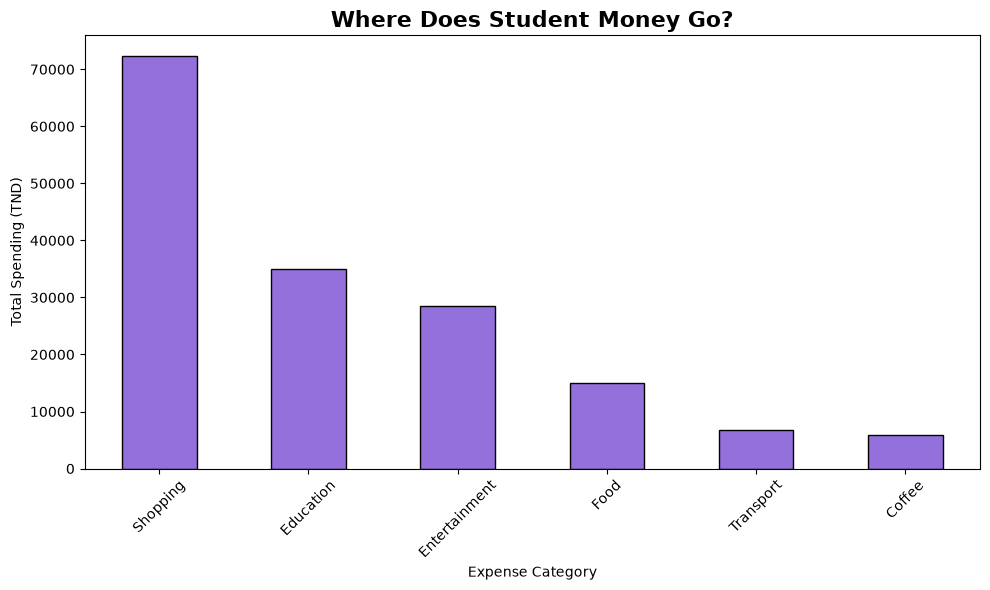

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

category_spending.plot(
    kind="bar",
    color="mediumpurple",
    edgecolor="black"
)

plt.title(
    "Where Does Student Money Go?",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Expense Category")
plt.ylabel("Total Spending (TND)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()